<a href="https://colab.research.google.com/github/gangambikaavanti/ai_lab_programs/blob/main/1bm24cs101_week9_FOL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Number of clauses: 2
Clause 1: ~Human(x) V Mortal(x)
Clause 2: Human(Socrates)
Goal to prove:  Mortal(Socrates)
Step 1: Resolve C1 & C2 {'x': 'Socrates'}  -->  Mortal(Socrates)
Step 2: Resolve C1 & C3 {'x': 'Socrates'}  -->  ~Human(Socrates)
Step 3: Resolve C2 & C5 {}  -->  [] (Contradiction)

HENCE PROVED! Opening proof tree graph...


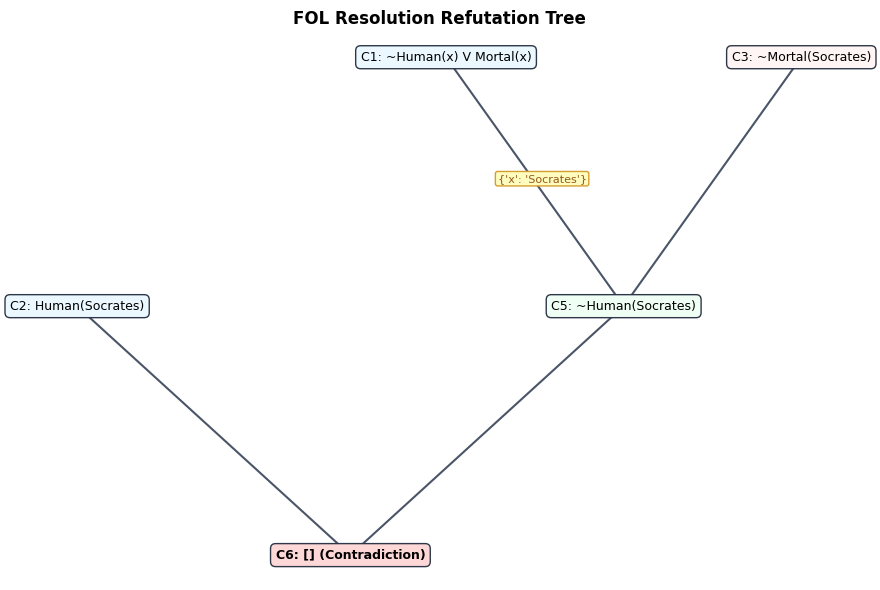


Cannot be proved.


In [5]:
import matplotlib.pyplot as plt


def is_var(x):
  return isinstance(x, str) and x.islower() and "(" not in x


def parse(lit):
  lit = lit.strip()
  neg = lit.startswith("~")
  if neg:
    lit = lit[1:]
  pred, args = lit[:-1].split("(")
  return (not neg, pred.strip(), [a.strip() for a in args.split(",")])


def show(clause):
  if not clause:
    return "[] (Contradiction)"
  return " V ".join(
      f"{'' if p else '~'}{pred}({', '.join(a)})" for p, pred, a in clause
  )


def unify(x, y, sub):
  if sub is None:
    return None
  if x == y:
    return sub
  if isinstance(x, list) and isinstance(y, list) and len(x) == len(y):
    for a, b in zip(x, y):
      sub = unify(a, b, sub)
    return sub
  if is_var(x):
    return {**sub, x: y}
  if is_var(y):
    return {**sub, y: x}
  return None


def resolve(c1, c2):
  for i, (p1, pr1, a1) in enumerate(c1):
    for j, (p2, pr2, a2) in enumerate(c2):
      if pr1 == pr2 and p1 != p2:
        sub = unify(a1, a2, {})
        if sub is not None:
          res = [
              (p, pr, [sub.get(x, x) for x in a])
              for k, (p, pr, a) in enumerate(c1 + c2)
              if k != i and k != len(c1) + j
          ]
          return res, sub
  return None, None


def draw_tree(kb, parents, empty_idx, neg_idx):
  fig, ax = plt.subplots(figsize=(9, 6))
  ax.axis("off")

  # Collect only nodes used in the final proof
  used = set()

  def trace(idx):
    if idx in used:
      return
    used.add(idx)
    if parents[idx]:
      trace(parents[idx][0])
      trace(parents[idx][1])

  trace(empty_idx)

  # Assign clean (x, y) positions bottom-up
  pos = {}

  def place(idx, x, y, dx):
    pos[idx] = (x, y)
    if parents[idx]:
      p1, p2, _ = parents[idx]
      place(p1, x - dx, y + 1.5, dx * 0.65)
      place(p2, x + dx, y + 1.5, dx * 0.65)

  place(empty_idx, 0, 0, 2.2)

  # Draw lines and substitution labels
  for idx in used:
    if parents[idx]:
      p1, p2, sub = parents[idx]
      x0, y0 = pos[idx]
      for p in (p1, p2):
        x1, y1 = pos[p]
        ax.plot([x1, x0], [y1, y0], color="#4a5568", lw=1.5, zorder=1)
      if sub:
        mx, my = (pos[p1][0] + x0) / 2 - 0.3, (pos[p1][1] + y0) / 2
        ax.text(
            mx,
            my,
            str(sub),
            fontsize=8,
            color="#975a16",
            bbox=dict(boxstyle="round,pad=0.2", fc="#fefcbf", ec="#d69e2e"),
        )

  # Draw clause boxes
  for idx in used:
    x, y = pos[idx]
    color = "#ebf8ff"  # KB clause (Blue)
    if idx == neg_idx:
      color = "#fff5f5"  # Negated goal (Red)
    elif idx == empty_idx:
      color = "#fed7d7"  # Contradiction (Dark Red)
    elif parents[idx]:
      color = "#f0fff4"  # Derived clause (Green)

    ax.text(
        x,
        y,
        f"C{idx+1}: {show(kb[idx])}",
        ha="center",
        va="center",
        fontsize=9,
        fontweight="bold" if idx == empty_idx else "normal",
        bbox=dict(boxstyle="round,pad=0.4", fc=color, ec="#2d3748"),
    )

  plt.title("FOL Resolution Refutation Tree", fontsize=12, fontweight="bold")
  plt.tight_layout()
  plt.show()


# --- User Input ---
n = int(input("Number of clauses: "))
kb = [[parse(l) for l in input(f"Clause {i+1}: ").split("V")] for i in range(n)]

goal = parse(input("Goal to prove: "))
kb.append([(not goal[0], goal[1], goal[2])])  # Add negated goal
neg_idx = len(kb) - 1
parents = {i: None for i in range(len(kb))}

# --- Resolution Loop ---
step = 1
while True:
  added = False
  for i in range(len(kb)):
    for j in range(i + 1, len(kb)):
      res, sub = resolve(kb[i], kb[j])
      if res is not None and res not in kb:
        kb.append(res)
        cur_idx = len(kb) - 1
        parents[cur_idx] = (i, j, sub)
        print(
            f"Step {step}: Resolve C{i+1} & C{j+1} {sub}  -->  {show(res)}"
        )
        step += 1
        if not res:
          print("\nHENCE PROVED! Opening proof tree graph...")
          draw_tree(kb, parents, cur_idx, neg_idx)
          exit()
        added = True
  if not added:
    print("\nCannot be proved.")
    break